# Evaluation and robustness
Train in the terminal with `python -m medical_gradcam train`, then use this notebook for results.
Select the project's `.venv` kernel and run from the project directory. No training happens here.

The notebook loads the best checkpoint saved by terminal training.
Check the selected checkpoint below. Use validation to choose settings; reserve the test set
for final comparisons. Heatmaps are model attributions, not lesion annotations.


In [1]:
import json
from pathlib import Path

import torch
import matplotlib.pyplot as plt
from IPython.display import Image as DisplayImage, Markdown, display

from medical_gradcam.config import Config
from medical_gradcam.evaluate import evaluate
from medical_gradcam.explain import explain
from medical_gradcam.robustness import robustness

config = Config.load("config.json")
run_dir = Path(config.run_dir)
checkpoint = run_dir / "best.pt"
if not checkpoint.exists():
    raise FileNotFoundError("No checkpoint found. Train in the terminal first.")
print("Checkpoint:", checkpoint.resolve())
saved = torch.load(checkpoint, map_location="cpu", weights_only=True)
best_epoch = saved["epoch"]
best_validation = saved["validation"]
print(f"Best epoch: {best_epoch} | validation loss: {best_validation['loss']:.4f} | "
      f"validation accuracy: {best_validation['accuracy']:.2%}")
del saved


Checkpoint: D:\Computer vision\medical_gradcam\runs\baseline\best.pt
Best epoch: 6 | validation loss: 0.0255 | validation accuracy: 98.85%


## Training history and selected epoch
`history.json` stores every epoch; `best.pt` stores the checkpoint with the highest
validation accuracy, using lower validation loss to break ties. Dashed lines mark
that selected epoch. Test results are not used to select it.


In [2]:
history_path = run_dir / "history.json"
if history_path.exists():
    history = json.loads(history_path.read_text(encoding="utf-8"))
    epochs = [row["epoch"] for row in history]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for split in ("train", "val"):
        axes[0].plot(epochs, [row[split]["loss"] for row in history], marker="o", label=split)
        axes[1].plot(epochs, [row[split]["accuracy"] for row in history], marker="o", label=split)
    for ax, title in zip(axes, ("Loss", "Accuracy")):
        ax.axvline(best_epoch, linestyle="--", color="gray", label=f"Best epoch: {best_epoch}")
        ax.set(title=title, xlabel="Epoch")
        ax.set_xticks(epochs)
        ax.legend()
        ax.grid(alpha=0.2)
    axes[1].set_ylim(0, 1.05)
    fig.tight_layout()
    display(fig)
    plt.close(fig)
else:
    print("No training history for this checkpoint. Curves appear after terminal training.")


<Figure size 1200x400 with 2 Axes>

## Classification metrics
Evaluate all test images by default; set `evaluation_split = "val"` for validation.
The table includes per-class precision, recall, F1 and image counts. Pneumonia recall
is sensitivity; NORMAL recall is specificity. ROC-AUC and Pneumonia AP use predicted
probabilities across thresholds; the confusion matrix uses the selected class.
IoU and detection mAP are omitted because the dataset has no location annotations.


test: 624/624 images | accuracy 0.8654
Confusion matrix (rows=true, columns=predicted): [[152, 82], [2, 388]]
Saved metrics and predictions to runs\baseline\evaluation
Split: test | Images: 624/624
Patient separation verified: False


| Metric | Value |
|---|---:|
| Accuracy | 86.54% |
| Macro F1 | 0.8429 |
| Pneumonia sensitivity (recall) | 99.49% |
| Specificity (NORMAL recall) | 64.96% |
| ROC-AUC | 0.9650 |
| Pneumonia AP | 0.9698 |
| Brier score (lower is better) | 0.1146 |
| Calibration error (lower is better) | 0.0854 |

| Class / average | Precision | Recall | F1 | Images |
|---|---:|---:|---:|---:|
| NORMAL | 0.9870 | 0.6496 | 0.7835 | 234 |
| PNEUMONIA | 0.8255 | 0.9949 | 0.9023 | 390 |
| macro avg | 0.9063 | 0.8222 | 0.8429 | 624 |
| weighted avg | 0.8861 | 0.8654 | 0.8578 | 624 |

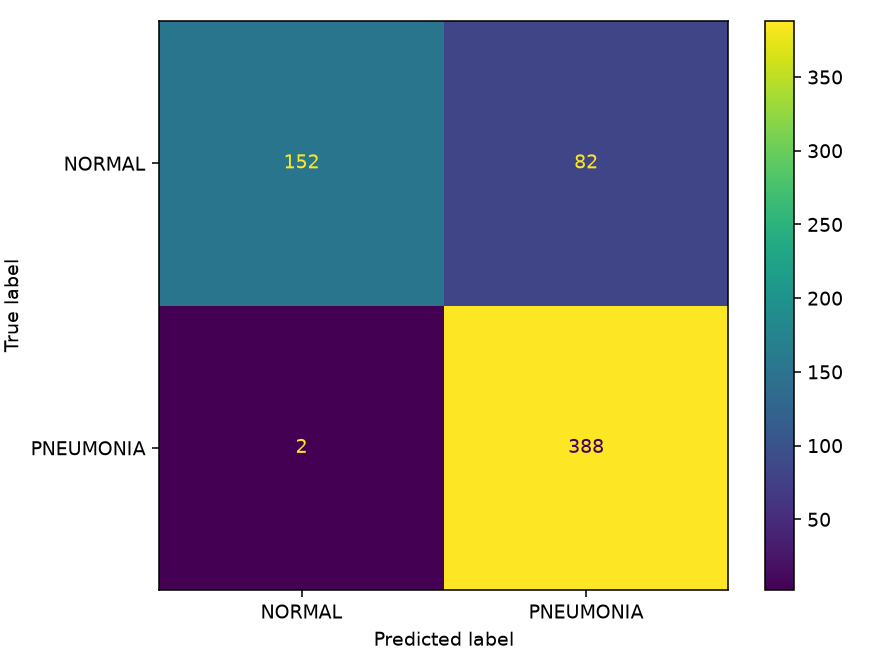

In [3]:
evaluation_split = "test"
metrics = evaluate(config, checkpoint, split=evaluation_split)
evaluation_dir = run_dir / ("evaluation" if evaluation_split == "test" else "validation")
report = metrics["classification_report"]

def score_text(value):
    return "Unavailable (requires both classes)" if value is None else f"{value:.4f}"

summary = [
    ("Accuracy", f"{metrics['accuracy']:.2%}"),
    ("Macro F1", f"{report['macro avg']['f1-score']:.4f}"),
    ("Pneumonia sensitivity (recall)", f"{report['PNEUMONIA']['recall']:.2%}"),
    ("Specificity (NORMAL recall)", f"{report['NORMAL']['recall']:.2%}"),
    ("ROC-AUC", score_text(metrics["roc_auc"])),
    ("Pneumonia AP", score_text(metrics["average_precision"])),
    ("Brier score (lower is better)", f"{metrics['brier_score']:.4f}"),
    ("Calibration error (lower is better)", f"{metrics['expected_calibration_error']:.4f}"),
]
print(f"Split: {metrics['split']} | Images: {metrics['sample_count']}/{metrics['total_available']}")
print("Patient separation verified:", metrics["patient_separation_verified"])
rows = ["| Metric | Value |", "|---|---:|"]
rows.extend(f"| {name} | {value} |" for name, value in summary)
display(Markdown("\n".join(rows)))
rows = ["| Class / average | Precision | Recall | F1 | Images |", "|---|---:|---:|---:|---:|"]
for name in metrics["classes"] + ["macro avg", "weighted avg"]:
    values = report[name]
    rows.append(f"| {name} | {values['precision']:.4f} | {values['recall']:.4f} | "
                f"{values['f1-score']:.4f} | {int(values['support'])} |")
display(Markdown("\n".join(rows)))
display(DisplayImage(filename=str(evaluation_dir / "confusion_matrix.png")))


## ROC and precision-recall curves
The dashed ROC diagonal is a chance reference. The dashed precision-recall line is
the pneumonia prevalence in this evaluation split. AP summarizes precision-recall
ranking; it is not detection mAP. Both curves require both ground-truth classes.


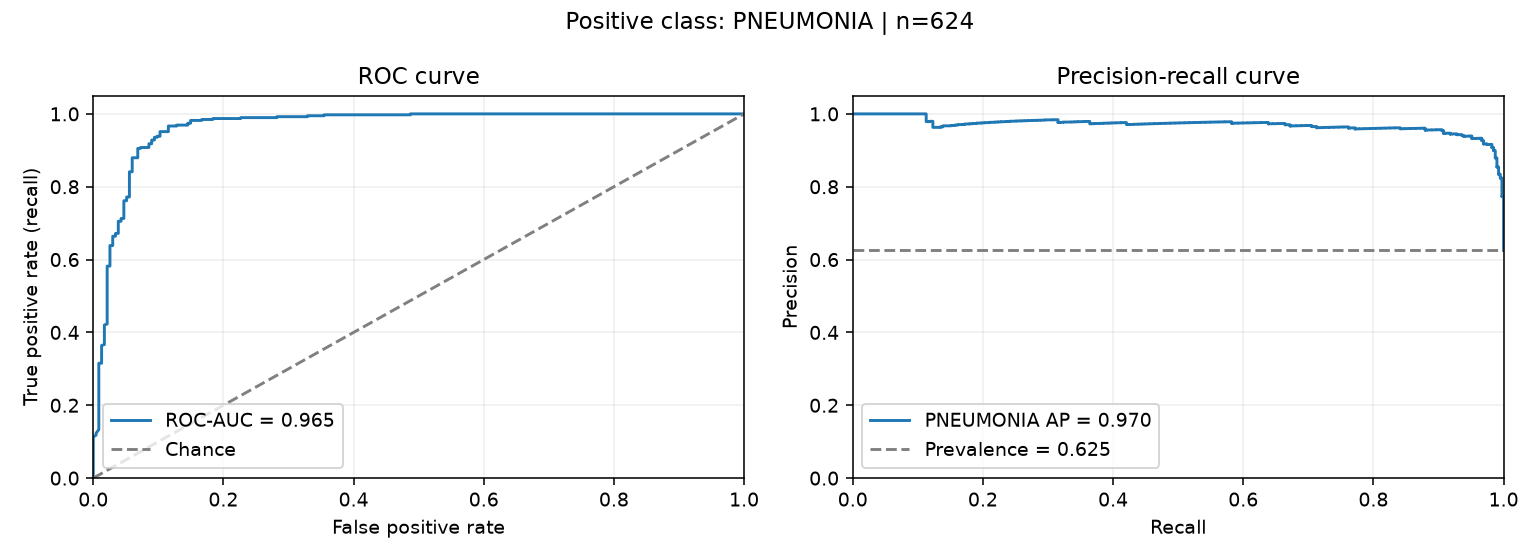

In [4]:
display(DisplayImage(filename=str(evaluation_dir / "ranking_curves.png")))


## Grad-CAM on one example
By default, choose the first incorrect prediction if there is one. Change `image_path`
to inspect another image. Compare methods by changing `method` to `"gradcam++"`.


Image: data\test\NORMAL\IM-0006-0001.jpeg
True: NORMAL | Predicted: PNEUMONIA
Saved heatmap, overlay and comparison to runs\baseline\explanations\IM-0006-0001\gradcam


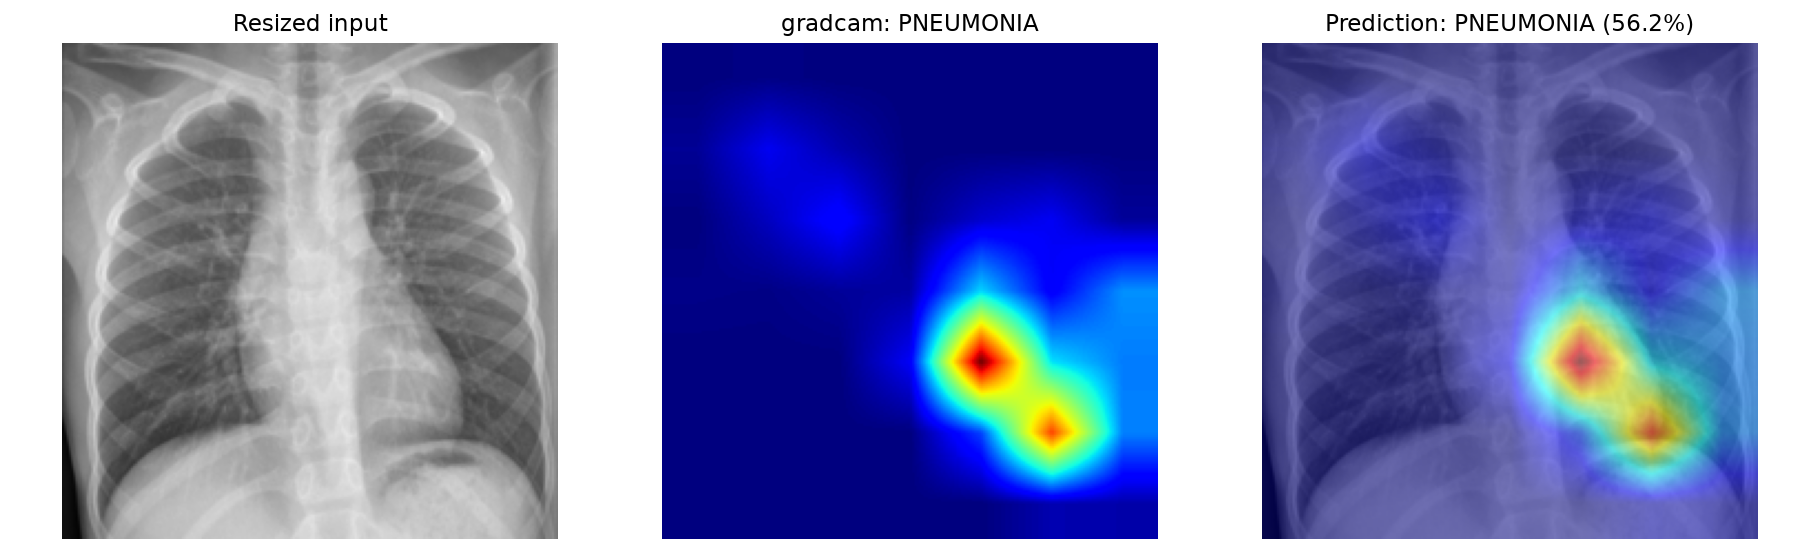

In [5]:
predictions = json.loads((evaluation_dir / "predictions.json").read_text(encoding="utf-8"))
incorrect = [row for row in predictions if row["true"] != row["predicted"]]
case = (incorrect or predictions)[0]
image_path = Path(config.data_dir) / case["path"]
method = "gradcam"
print("Image:", image_path)
print("True:", case["true"], "| Predicted:", case["predicted"])
explain(config, checkpoint, image_path, method=method)
comparison = run_dir / "explanations" / image_path.stem / method / "comparison.png"
display(DisplayImage(filename=str(comparison)))


## Robustness experiments
Compare border masking, equal-area central masking, brightness changes and translation.
The default is a seeded sample of 100 validation images for a new checkpoint.
Prediction changes alone do not prove shortcut learning.


In [6]:
robustness_split = "val"
robustness_limit = 100
robustness(config, checkpoint, split=robustness_split, limit=robustness_limit)
robustness_dir = run_dir / "robustness" / robustness_split
results = json.loads((robustness_dir / "results.json").read_text(encoding="utf-8"))
print("Sample size:", results["sample_count"], "of", results["total_available"])
print(results["limitations"])
rows = ["| Variant | Accuracy | Prediction flip rate | Mean probability change |",
        "|---|---:|---:|---:|"]
for name, values in results["summary"].items():
    rows.append(f"| {name} | {values['accuracy']:.2%} | {values['prediction_flip_rate']:.2%} | "
                f"{values['mean_original_class_probability_change']:+.4f} |")
display(Markdown("\n".join(rows)))


Saved robustness results for 100 val images to runs\baseline\robustness\val
Sample size: 100 of 1044
Perturbations can remove useful information and cause distribution shift. Sensitivity alone does not prove shortcut learning. No lung segmentation is used.


| Variant | Accuracy | Prediction flip rate | Mean probability change |
|---|---:|---:|---:|
| original | 99.00% | 0.00% | +0.0000 |
| border_mask | 97.00% | 2.00% | -0.0383 |
| center_mask_control | 96.00% | 3.00% | -0.0454 |
| brightness_0.9 | 99.00% | 0.00% | +0.0006 |
| brightness_1.1 | 98.00% | 1.00% | -0.0036 |
| translate_right_5pct | 99.00% | 0.00% | -0.0007 |

**original**

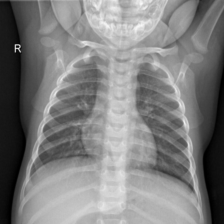

**border_mask**

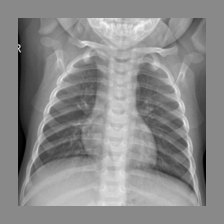

**center_mask_control**

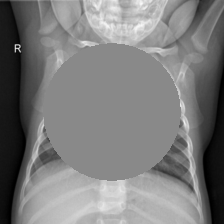

**brightness_0.9**

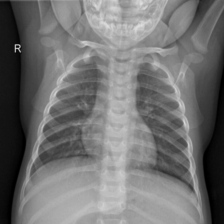

**brightness_1.1**

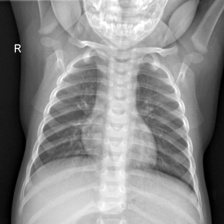

**translate_right_5pct**

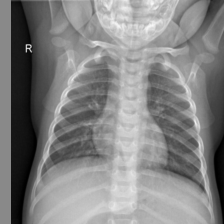

In [7]:
for variant in results["summary"]:
    display(Markdown(f"**{variant}**"))
    display(DisplayImage(filename=str(robustness_dir / f"example_{variant}.png"), width=260))
